# Silver V1 · Exploratory Data Analysis

**Goal:** Assess whether the existing VTSNLP Silver snapshot is ready for Gold. This notebook **does not modify** Bronze/Silver, train models, or create Gold splits.

**Visuals generated from real data:** class-frequency chart, document-length histogram, length-by-domain boxplots, noise-indicator bars, label/noise heatmap, and Bronze → Silver comparison. It also prints a bounded-sample near-duplicate table.

Run in a repository checkout (Jupyter, VS Code or Colab), after installing \`python -m pip install -e ".[eda]"\`. Mount or synchronize the correct Data Lake directory and set \`DATA_LAKE_ROOT\` in your environment or \`.env\`. In Colab, clone the feature branch and change working directory to the cloned repository before starting.

Checksums establish data integrity, **not** semantic correctness of VTSNLP's topic labels. This is not a moderation-label dataset.

In [12]:
from pathlib import Path
from collections import Counter
from IPython.display import display
import hashlib, json, os, random, re, sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

working = Path.cwd().resolve()
repo = next((p for p in (working, *working.parents)
             if (p / "pyproject.toml").exists()
             and (p / "src/vietnamese_topic_classification").is_dir()), None)
if repo is None:
    raise RuntimeError("Run notebook in a clone of this repository")
sys.path.insert(0, str(repo / "src"))
from vietnamese_topic_classification.config.settings import DataLakeConfig
from vietnamese_topic_classification.data.bronze import BronzeReader, BronzeException
from vietnamese_topic_classification.data.silver import SilverReader, SilverTransformer

plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (11, 5),
                     "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 10})
COLORS = {"blue": "#2878B5", "teal": "#009F93", "red": "#D7646C", "amber": "#D59432"}
figures = {}

## 0. Configuration and integrity verification

Set \`SILVER_REPORT_NAME\` to the **actual** file in \`05_reports/\`. SilverReader verifies accepted-row count and SHA-256 before analysis. \`EXPORT_RESULTS=False\` ensures no files are written.

In [13]:
DATA_LAKE_ROOT_OVERRIDE = None  # e.g. r"E:\data\vietnamese-multilabel-topic-classification"
SILVER_REPORT_NAME = "silver_quality_v1_b81fcce589_seed42_buf10000_n50000.json"
BRONZE_MANIFEST_OVERRIDE = None
COMPARE_BRONZE = True
EXPORT_RESULTS = False
SIMILARITY_SAMPLE_SIZE = 700
SIMILARITY_THRESHOLD = 0.90
SEED = 42

root = (Path(DATA_LAKE_ROOT_OVERRIDE).expanduser() if DATA_LAKE_ROOT_OVERRIDE
        else DataLakeConfig.from_env().root)
silver = SilverReader(data_lake_root=root, metadata_name=SILVER_REPORT_NAME)
verified = silver.verify()
print("Silver verified:", verified)
print("Snapshot:", silver.data_path)
print("Source manifest:", silver.report.get("source_manifest", "(not provided)"))

Silver verified: {'valid': True, 'records': 50000, 'sha256': '8cadceaf8fd005f77d5350d15e4bdaf26bd6f2ce07b6ffc7886d62ef4b1ea9c1'}
Snapshot: G:\My Drive\vietnamese-multilabel-topic-classification\02_silver\vtsnlp_silver_v1_b81fcce589_seed42_buf10000_n50000.jsonl
Source manifest: source_manifest_b81fcce589_seed42_buf10000_n50000.json


## 1. Dataset profile and basic quality checks

Stream all accepted Silver records but store only compact metrics in memory. Check required fields, \`text_length\`, duplicate IDs and exact duplicate text hashes. Keep at most 700 short article excerpts for sampled similarity diagnostics.

In [14]:
PATTERNS = {
    "boilerplate": re.compile(r"quảng\s*cáo|bạn\s+đang\s+xem|xem\s+thêm|"
                              r"bài\s+viết\s+liên\s+quan|có\s+thể\s+bạn\s+quan\s+tâm|"
                              r"toplist|xem\s+nhiều", re.I),
    "url": re.compile(r"https?://\S+|www\.\S+", re.I),
    "html_tag": re.compile(r"</?[A-Za-z][^>]{0,180}>"),
    "replacement_char": re.compile("\ufffd"),
}
REQUIRED = ("id", "text", "domain", "text_length", "source_snapshot", "quality_flags")
rng = random.Random(SEED)
missing, text_hashes = Counter(), Counter()
length_mismatch, duplicate_ids = 0, 0
seen_silver = {}
features, sampled_articles, flagged_examples = [], [], []
for i, record in enumerate(silver.iter_records()):
    for key in REQUIRED:
        value = record.get(key)
        if value is None or (isinstance(value, str) and not value.strip()):
            missing[key] += 1
    text = record.get("text")
    text = text if isinstance(text, str) else ""
    rid = record.get("id")
    rid = rid.strip() if isinstance(rid, str) else ""
    domain = record.get("domain")
    domain = domain if isinstance(domain, str) else "<invalid>"
    flags = {k: bool(p.search(text)) for k, p in PATTERNS.items()}
    sha = hashlib.sha256(text.encode("utf-8")).hexdigest()
    text_hashes[sha] += 1
    if type(record.get("text_length")) is not int or record["text_length"] != len(text):
        length_mismatch += 1
    if rid in seen_silver:
        duplicate_ids += 1
    else:
        seen_silver[rid] = (sha, domain)
    features.append(dict(id=rid, domain=domain, chars=len(text),
                         words=len(text.split()), lines=text.count("\n") + int(bool(text)), **flags))
    if flags["boilerplate"] and len(flagged_examples) < 6:
        flagged_examples.append(dict(id=rid, domain=domain, preview=text[:240].replace("\n", " ⏎ ")))
    entry = (rid, domain, text[:4000])
    if len(sampled_articles) < SIMILARITY_SAMPLE_SIZE:
        sampled_articles.append(entry)
    else:
        j = rng.randrange(i + 1)
        if j < SIMILARITY_SAMPLE_SIZE:
            sampled_articles[j] = entry

df = pd.DataFrame(features)
if df.empty:
    raise ValueError("Silver contains no accepted rows")
if len(df) != verified["records"]:
    raise AssertionError("Silver record count changed after verification")
exact_extra = sum(count - 1 for count in text_hashes.values() if count > 1)
profile = {
    "records": len(df), "domains": df.domain.nunique(),
    "missing_required": dict(missing), "text_length_mismatches": length_mismatch,
    "duplicate_ids": duplicate_ids, "exact_duplicate_extra_rows": exact_extra,
    "report_input_rows": silver.report.get("input_rows"),
    "report_accepted_rows": silver.report.get("accepted_rows"),
    "report_rejected_rows": silver.report.get("rejected_rows"),
    "rejection_reasons": silver.report.get("rejection_reasons", {}),
}
display(pd.DataFrame([{"metric": k, "value": str(v)} for k, v in profile.items()]))
if len(df) != silver.report["accepted_rows"]:
    raise AssertionError("EDA and Silver report disagree on record count")

,metric,value
0,records,50000
1,domains,25
2,missing_required,{}
3,text_length_mismatches,0
4,duplicate_ids,0
5,exact_duplicate_extra_rows,0
6,report_input_rows,50000
7,report_accepted_rows,50000
8,report_rejected_rows,0
9,rejection_reasons,{}


## 2. Distribution of 25 source-domain labels

Class imbalance helps determine Gold stratification and downstream macro-F1 evaluation. Source-domain labels have **not** been manually validated.

,count,pct
domain,,
Arts_and_Entertainment,3789,7.58
Health,3648,7.30
People_and_Society,3473,6.95
Sports,3329,6.66
News,3006,6.01
Sensitive_Subjects,2897,5.79
Food_and_Drink,2851,5.70
Business_and_Industrial,2638,5.28
Travel_and_Transportation,2421,4.84


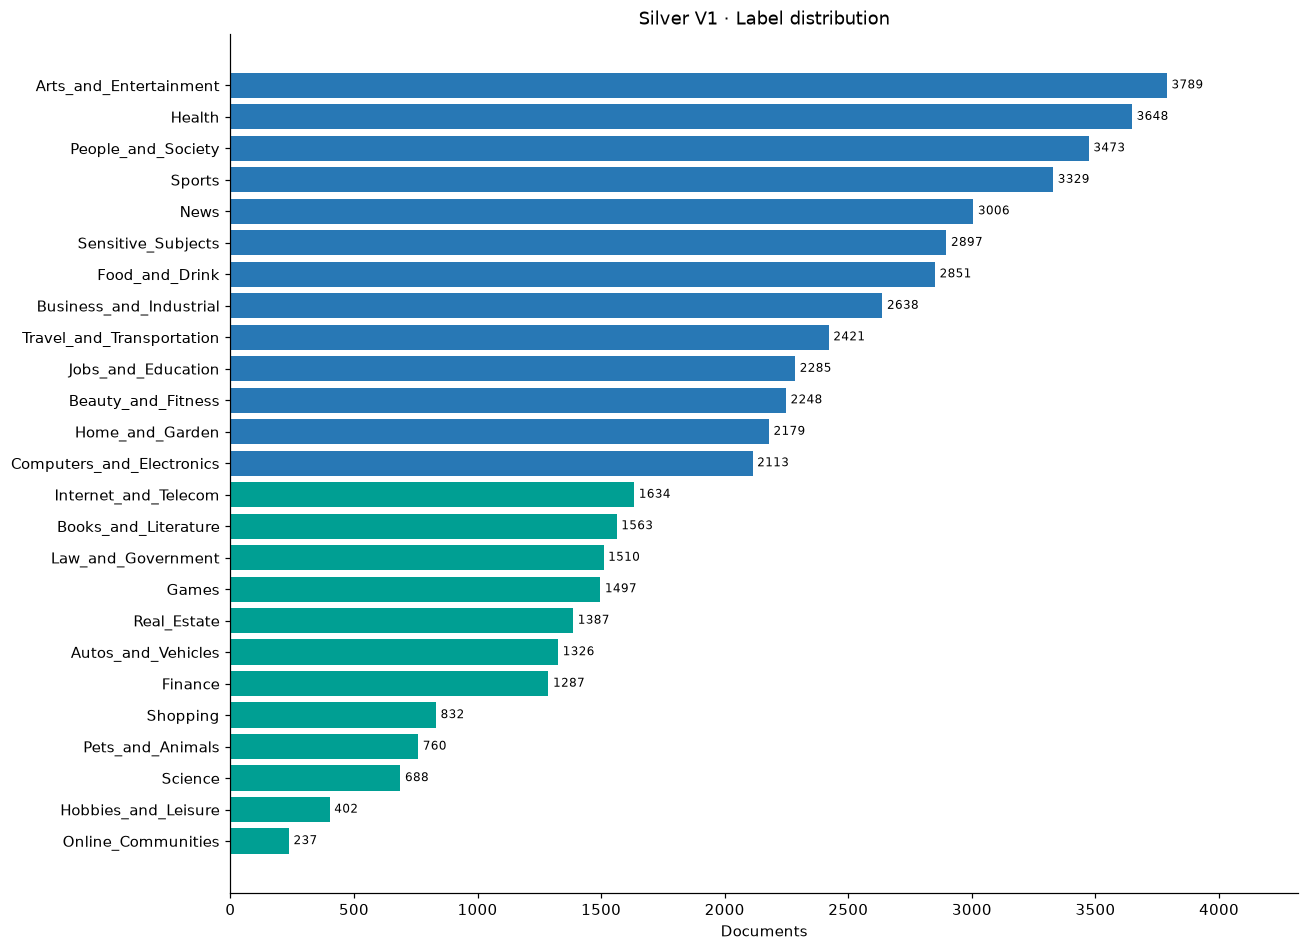

Max/min class size ratio: 15.99


In [15]:
counts = df.domain.value_counts()
display(pd.DataFrame({"count": counts, "pct": (100 * counts / len(df)).round(2)}))
ordered = counts.sort_values()
fig, ax = plt.subplots(figsize=(12, max(6, len(counts) * .35)))
bars = ax.barh(ordered.index, ordered.values,
               color=[COLORS["teal"] if x < counts.median() else COLORS["blue"] for x in ordered])
ax.bar_label(bars, padding=3, fontsize=8)
ax.set_xlim(0, counts.max() * 1.14)
ax.set(xlabel="Documents", title="Silver V1 · Label distribution")
fig.tight_layout()
figures["01_domain_distribution"] = fig
plt.show()
print("Max/min class size ratio:", round(counts.max() / counts.min(), 2))

## 3. Document lengths and outliers

\`words\` is a whitespace-based approximation, **not** tokenizer token count. Gold should not truncate text; decide model-specific truncation later.

,chars,words,lines
count,50000.0,50000.0,50000.0
mean,4243.3,917.1,28.5
std,5882.6,1272.2,45.8
min,206.0,50.0,1.0
50%,2858.0,617.0,16.0
90%,8152.1,1765.0,63.0
95%,11534.1,2494.0,92.0
99%,25550.5,5560.0,201.0
max,175203.0,39027.0,3408.0


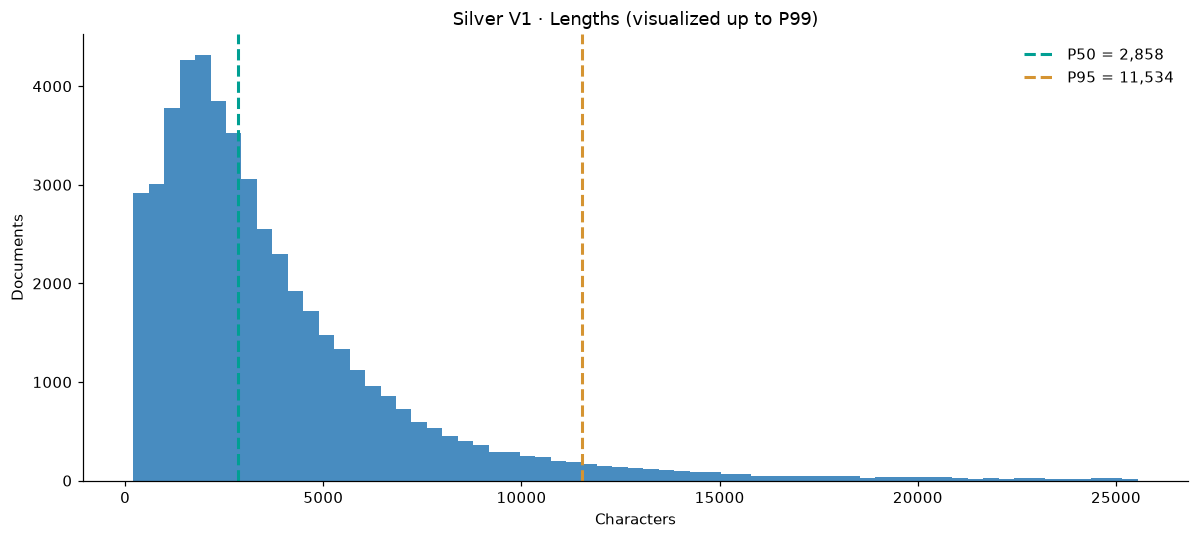

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_35532\2449745426.py:18: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bp = ax.boxplot(


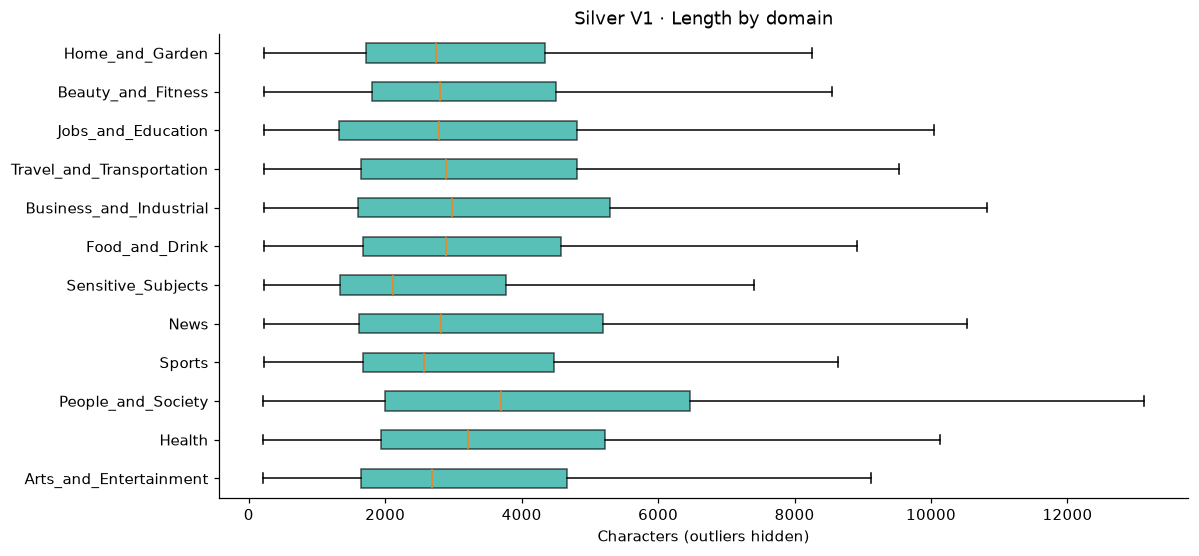

In [16]:
display(df[["chars", "words", "lines"]].describe(percentiles=[.5, .9, .95, .99]).round(1))
p99 = max(1, float(df.chars.quantile(.99)))
fig, ax = plt.subplots(figsize=(11, 5))
ax.hist(df.loc[df.chars <= p99, "chars"], bins=65, color=COLORS["blue"], alpha=.85)
for q, color in [(.5, COLORS["teal"]), (.95, COLORS["amber"])]:
    value = float(df.chars.quantile(q))
    ax.axvline(value, ls="--", lw=2, color=color, label=f"P{int(q*100)} = {value:,.0f}")
ax.set(xlabel="Characters", ylabel="Documents", title="Silver V1 · Lengths (visualized up to P99)")
ax.legend(frameon=False)
fig.tight_layout()
figures["02_length_histogram"] = fig
plt.show()

top = counts.head(min(len(counts), 12)).index.tolist()

fig, ax = plt.subplots(figsize=(11, max(5, .43 * len(top))))

bp = ax.boxplot(
    [df.loc[df.domain == domain, "chars"] for domain in top],
    vert=False,
    showfliers=False,
    patch_artist=True
)

ax.set_yticks(range(1, len(top) + 1))
ax.set_yticklabels(top)

for patch in bp["boxes"]:
    patch.set(facecolor=COLORS["teal"], alpha=.65)

ax.set(
    xlabel="Characters (outliers hidden)",
    title="Silver V1 · Length by domain"
)

fig.tight_layout()
figures["03_length_by_domain"] = fig
plt.show()

## 4. Crawl-noise indicators

Heuristics flag boilerplate/navigation phrases, URLs, HTML remnants and replacement characters. **A match does not prove a record is bad.** Review the examples before proposing any Silver V2 cleaning.

,flagged,rate_%
replacement_char,136,0.27
html_tag,283,0.57
url,5511,11.02
boilerplate,7313,14.63


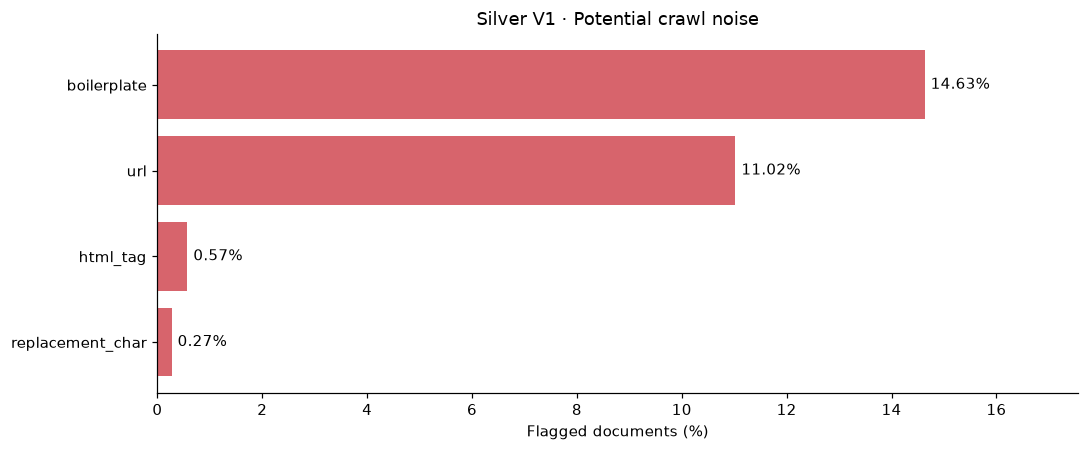

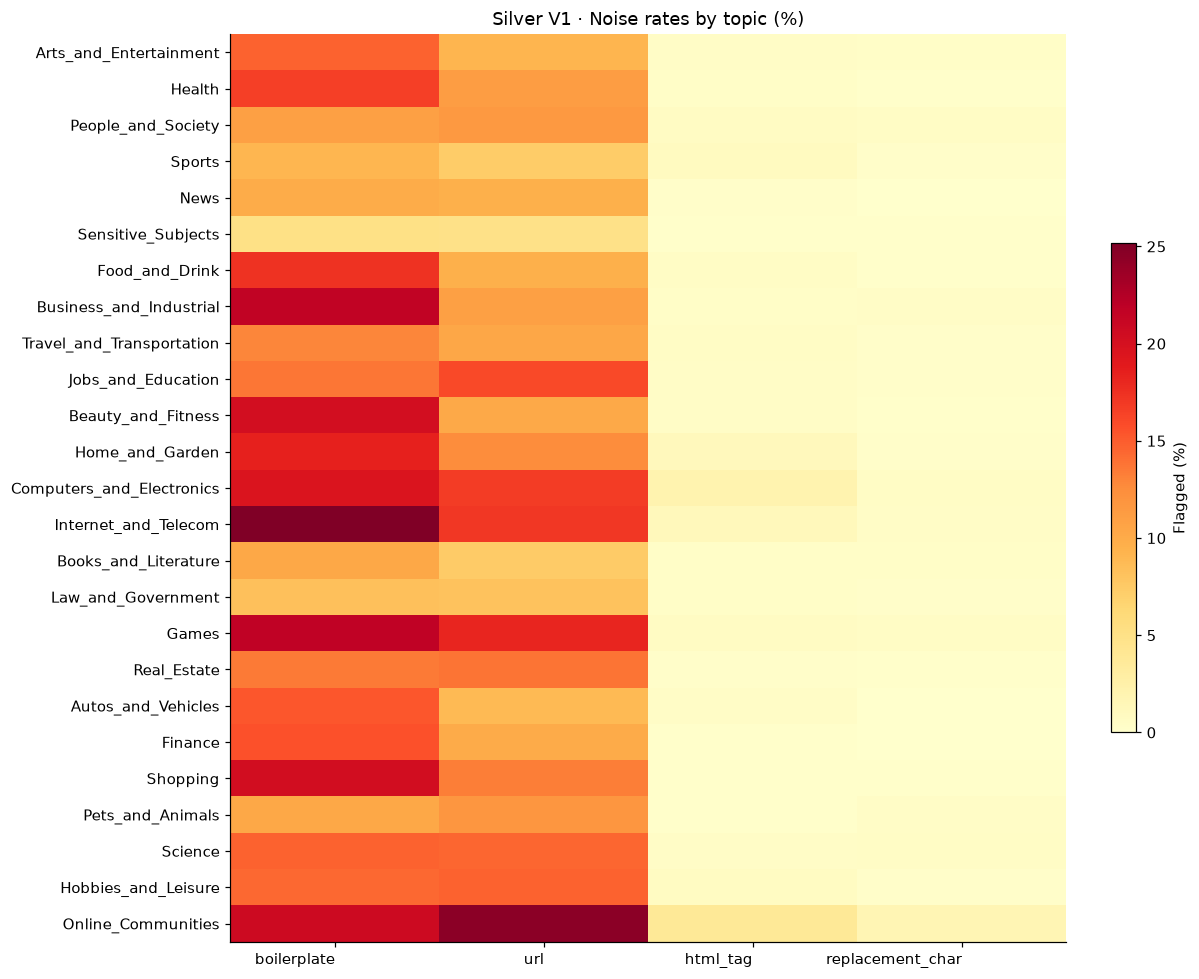

,id,domain,preview
0,VI_open-0003286518,Games,Minecraft luôn luôn dành những điều bất thần c...
1,VI_open-0003286174,Jobs_and_Education,Nhiều bạn học xong một thời gian không dùng tớ...
2,VI_open-0003287045,Beauty_and_Fitness,Gọt mặt nội soi là phương pháp hiệu quả toàn d...
3,VI_open-0003290575,Home_and_Garden,"Từ 24/11/2014, Kitchen Art Store sẽ chính thức..."
4,VI_open-0003322476,Food_and_Drink,Món ăn Nhật Bản nổi tiếng trên khắp thế giới k...
5,VI_open-0003314626,Food_and_Drink,Cháo lòng Huế là một món ăn trứ danh và đầy cô...


In [21]:
noise_cols = list(PATTERNS)
noise_counts = df[noise_cols].sum().sort_values()
noise_pct = (100 * noise_counts / len(df)).round(2)
display(pd.DataFrame({"flagged": noise_counts, "rate_%": noise_pct}))
fig, ax = plt.subplots(figsize=(10, 4.2))
bars = ax.barh(noise_pct.index, noise_pct.values, color=COLORS["red"])
ax.bar_label(bars, fmt="%.2f%%", padding=4)
ax.set_xlim(0, max(1, noise_pct.max() * 1.20))
ax.set(xlabel="Flagged documents (%)", title="Silver V1 · Potential crawl noise")
fig.tight_layout()
figures["04_noise_indicators"] = fig
plt.show()

heat = 100 * df.groupby("domain")[noise_cols].mean().loc[counts.index]
fig, ax = plt.subplots(figsize=(11, max(6, .36 * len(heat))))
im = ax.imshow(heat.values, cmap="YlOrRd", vmin=0, aspect="auto")
ax.set_xticks(range(len(noise_cols)), noise_cols, rotation=0, ha="right")
ax.set_yticks(range(len(heat)), heat.index)
ax.set_title("Silver V1 · Noise rates by topic (%)")
fig.colorbar(im, ax=ax, label="Flagged (%)", fraction=.027)
fig.tight_layout()
figures["05_noise_heatmap"] = fig
plt.show()
display(pd.DataFrame(flagged_examples))

## 5. Bronze → Silver: what actually changed?

Use Silver quality-report \`source_manifest\` to find Bronze. Compare text SHA-256 by **unique IDs**, not by record position; duplicate Bronze IDs are marked ambiguous. This is a read-only diagnostic. An unavailable Bronze snapshot is reported as skipped rather than silently treated as unchanged.

{
  "status": "completed",
  "bronze_rows": 50000,
  "silver_rows": 50000,
  "duplicate_bronze_id_groups": 0,
  "text_comparison": {
    "domain_changed": 0,
    "unchanged_text": 46176,
    "normalization_only": 3824
  }
}


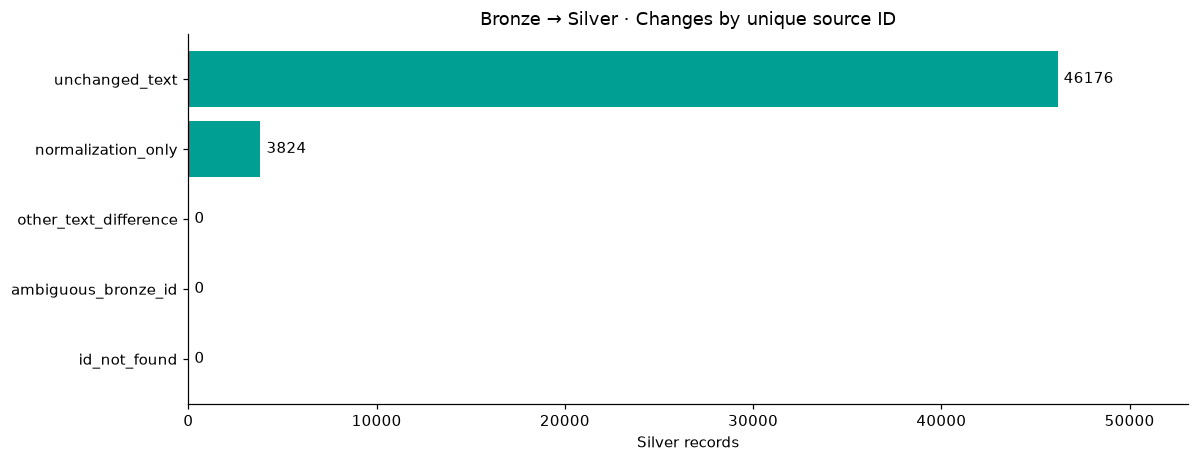

In [18]:
comparison = {"status": "skipped", "reason": "Bronze comparison disabled"}
if COMPARE_BRONZE:
    source_manifest = BRONZE_MANIFEST_OVERRIDE or silver.report.get("source_manifest")
    if not source_manifest:
        comparison = {"status": "skipped", "reason": "No source_manifest in Silver quality report"}
    else:
        try:
            bronze = BronzeReader(data_lake_root=root, metadata_name=source_manifest)
            bronze_verified = bronze.verify()
        except (BronzeException, OSError) as exc:
            comparison = {"status": "skipped", "reason": f"Bronze unavailable: {exc}"}
        else:
            bronze_counts, bronze_unique = Counter(), {}
            for record in bronze.iter_records():
                rid = record.get("id")
                rid = rid.strip() if isinstance(rid, str) else ""
                bronze_counts[rid] += 1
                if bronze_counts[rid] != 1:
                    bronze_unique.pop(rid, None)
                    continue
                raw = record.get("text")
                raw = raw if isinstance(raw, str) else ""
                normalized = SilverTransformer.normalize_text(raw)
                bronze_unique[rid] = (hashlib.sha256(raw.encode()).hexdigest(),
                                      hashlib.sha256(normalized.encode()).hexdigest(),
                                      record.get("domain"))
            c = Counter()
            for rid, (silver_sha, silver_domain) in seen_silver.items():
                if bronze_counts[rid] > 1:
                    c["ambiguous_bronze_id"] += 1
                elif rid not in bronze_unique:
                    c["id_not_found"] += 1
                else:
                    original_sha, norm_sha, original_domain = bronze_unique[rid]
                    c["domain_changed"] += int(original_domain != silver_domain)
                    if silver_sha == original_sha:
                        c["unchanged_text"] += 1
                    elif silver_sha == norm_sha:
                        c["normalization_only"] += 1
                    else:
                        c["other_text_difference"] += 1
            comparison = {"status": "completed", "bronze_rows": bronze_verified["records"],
                          "silver_rows": len(df),
                          "duplicate_bronze_id_groups": sum(v > 1 for v in bronze_counts.values()),
                          "text_comparison": dict(c)}
print(json.dumps(comparison, indent=2, ensure_ascii=False))
if comparison["status"] == "completed":
    keys = ["unchanged_text", "normalization_only", "other_text_difference",
            "ambiguous_bronze_id", "id_not_found"]
    values = [comparison["text_comparison"].get(k, 0) for k in keys]
    fig, ax = plt.subplots(figsize=(11, 4.3))
    bars = ax.barh(keys[::-1], values[::-1], color=COLORS["teal"])
    ax.bar_label(bars, padding=4)
    ax.set_xlim(0, max(1, max(values) * 1.15))
    ax.set(xlabel="Silver records", title="Bronze → Silver · Changes by unique source ID")
    fig.tight_layout()
    figures["06_bronze_silver_comparison"] = fig
    plt.show()

## 6. Sampled near-duplicate candidates

Use TF-IDF word 1–2 grams and cosine similarity over a seeded reservoir of up to 700 articles (each limited to 4,000 characters). **This is not an exhaustive leakage audit**; Gold still needs a full-dataset leakage strategy.

In [19]:
from sklearn.feature_extraction.text import TfidfVectorizer
pairs = []
if len(sampled_articles) >= 2:
    X = TfidfVectorizer(ngram_range=(1, 2), max_features=25000,
                        dtype=np.float32).fit_transform([row[2] for row in sampled_articles])
    sim = (X @ X.T).tocoo()
    for i, j, score in zip(sim.row, sim.col, sim.data):
        if i < j and score >= SIMILARITY_THRESHOLD:
            pairs.append({"id_a": sampled_articles[i][0],
                          "domain_a": sampled_articles[i][1],
                          "id_b": sampled_articles[j][0],
                          "domain_b": sampled_articles[j][1],
                          "cosine": round(float(score), 4)})
pairs.sort(key=lambda row: row["cosine"], reverse=True)
print(f"Sampled {len(sampled_articles)} articles; {len(pairs)} candidates at cosine >= {SIMILARITY_THRESHOLD}")
display(pd.DataFrame(pairs[:20]))

Sampled 700 articles; 0 candidates at cosine >= 0.9


""


## 7. Readiness for Gold and optional export

Review flagged examples, unexpected duplication, class balance, and near-duplicate candidates. **Do not interpret heuristic flags as labels or declare Gold ready automatically.** The full class distribution and snapshot lineage should inform Gold splitting.

Charts above display inline. Optional \`EXPORT_RESULTS=True\` saves summary JSON and all generated PNGs under \`05_reports/eda/<silver_snapshot_stem>/\`, without overwriting existing outputs. No raw text is written to the summary.

In [20]:
summary = {
    "silver_snapshot": silver.data_path.name,
    "silver_quality_report": silver.report_path.name,
    "silver_sha256": verified["sha256"],
    "profile": profile,
    "class_counts": {str(k): int(v) for k, v in counts.items()},
    "length_percentiles": {str(q): round(float(df.chars.quantile(q)), 1)
                           for q in (.5, .9, .95, .99)},
    "noise_flags": {key: int(df[key].sum()) for key in noise_cols},
    "bronze_comparison": comparison,
    "sampled_near_duplicate_count": len(pairs),
    "sample_size": len(sampled_articles),
    "similarity_threshold": SIMILARITY_THRESHOLD,
    "caveat": "Topic labels unverified; noise heuristics and sampled similarity are exploratory.",
}
checks = {
    "Required fields present": not any(missing.values()),
    "text_length values consistent": length_mismatch == 0,
    "No exact duplicate Silver text": exact_extra == 0,
    "No duplicate accepted IDs": duplicate_ids == 0,
}
display(pd.DataFrame({"quality_gate": checks.keys(), "pass": checks.values()}))
print("Manual review and full-dataset leakage checks are still required before Gold.")
if EXPORT_RESULTS:
    destination = root / "05_reports" / "eda" / silver.data_path.stem
    exports = [destination / "summary.json"] + [destination / f"{key}.png" for key in figures]
    existing = [str(path) for path in exports if path.exists()]
    if existing:
        raise FileExistsError(f"Refusing to overwrite EDA files: {existing}")
    destination.mkdir(parents=True, exist_ok=True)
    for key, fig in figures.items():
        fig.savefig(destination / f"{key}.png", dpi=170, bbox_inches="tight")
    with (destination / "summary.json").open("x", encoding="utf-8") as handle:
        json.dump(summary, handle, ensure_ascii=False, indent=2)
        handle.write("\n")
    print("Saved results:", destination)
else:
    print("EXPORT_RESULTS=False: no files were written")

,quality_gate,pass
0,Required fields present,True
1,text_length values consistent,True
2,No exact duplicate Silver text,True
3,No duplicate accepted IDs,True


Manual review and full-dataset leakage checks are still required before Gold.
EXPORT_RESULTS=False: no files were written
